# A Mathematical Approach to Sentinel-2 Time-Series Analysis for Retrospective Crop Verification

**SoftUni Mathematics and Python final project · Bulgaria · P001**

## Abstract
The study examines the mathematics of normalized difference vegetation indices, irregularly sampled time series, quality filtering and seasonal signals for one agricultural parcel. The objective is **interpretable retrospective evidence**, not a trained crop classifier. All values in the observational analysis come from the source CSV when supplied; no satellite observations are manufactured.

**Research question:** How do temporal sampling, quality selection and smoothing change the interpretation of Sentinel-2 NDVI and NDMI trajectories?

**Hypotheses:** (H1) Partial-coverage observations influence descriptive results; (H2) time-aware derivatives are preferable to plain differences for irregularly spaced timestamps; (H3) a 21-day rolling average captures broad phenological trends but can hide rapid events.


## 1. Mathematical foundations

For reflectance in the near-infrared (NIR), red (R), and short-wave infrared (SWIR):

$$\mathrm{NDVI}=\frac{NIR-R}{NIR+R},\qquad\mathrm{NDMI}=\frac{NIR-SWIR}{NIR+SWIR}.$$

The denominators must be nonzero. Under nonnegative reflectance, a normalized difference lies between -1 and 1; noise and other processing conditions complicate interpretation. NDVI measures relative spectral greenness rather than crop identity; NDMI relates to canopy water status and structure but is not a direct water-content measurement.

For irregular times $t_i$, use $$r_i=\frac{x_i-x_{i-1}}{t_i-t_{i-1}}.$$ This reports index units per day. Sample variance is $$s^2=\frac{1}{n-1}\sum_i(x_i-\bar x)^2.$$ For an estimate $\hat x$, $$RMSE=\sqrt{n^{-1}\sum_i(x_i-\hat x_i)^2}.$$

A time-window rolling average uses observations within a specified duration, rather than a fixed number of consecutive rows. The rolling average is descriptive; comparing it with observations from the same input does not constitute independent model validation.


In [1]:
from pathlib import Path
import sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if not (ROOT / 'src').exists() and (ROOT.parent / 'src').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.math_analysis import normalized_difference, rates_of_change, rolling_time_mean, summary, rmse
print('Working directory:', ROOT)
print('Mathematical identity check NDVI:', normalized_difference(0.8, 0.2))

Working directory: c:\Users\User\Documents\SoftUni_Sentinel_Monitoring
Mathematical identity check NDVI: 0.6000000000000001


## 2. Observational data and reproducibility

Original workflow: Sentinel-2 L2A, parcel P001 (Bulgaria), Sentinel Hub Statistical API with one-day aggregation buckets, nominal 20 m, scene classes SCL=4 (vegetation) and SCL=5 (bare soils) retained, and per-pixel normalized differences aggregated over the parcel. Masked pixels cannot yield valid index observations.

**Important:** the historical archive reported 141 daily rows, 70 valid dates, and 58 complete-coverage dates, spanning 2023-09-02 to 2024-08-27. These are provenance notes, **not recomputed results** unless the matching original CSV is recovered. No live acquisition is performed by this notebook.


In [2]:
DATA = ROOT / 'data' / 'results'
qa_path = DATA / 'time_series_p001_2023_2024_qa.csv'
raw_path = DATA / 'time_series_p001_2023_2024.csv'
if qa_path.exists():
    observed = pd.read_csv(qa_path)
    data_source = qa_path.name
elif raw_path.exists():
    observed = pd.read_csv(raw_path)
    data_source = raw_path.name
else:
    observed = None
    data_source = None
    print('ORIGINAL CSV NOT PRESENT: observational conclusions cannot be reproduced. Add your original CSV to data/results/.')

if observed is not None:
    df = observed.copy()
    df["date"] = pd.to_datetime(df["interval_from"], utc=True)

    valid = df[df["is_valid"] == "yes"].copy()
    complete = valid[valid["coverage_status"] == "complete"].copy()

    print(
        "Source:", data_source,
        "| rows:", len(df),
        "| valid:", len(valid),
        "| complete:", len(complete)
    )

    display(
        df[["date", "ndvi_mean", "ndmi_mean",
            "coverage_status", "qa_flags"]].head()
    )



Source: time_series_p001_2023_2024_qa.csv | rows: 141 | valid: 70 | complete: 58


,date,ndvi_mean,ndmi_mean,coverage_status,qa_flags
0,2023-09-02 00:00:00+00:00,0.152686,-0.278022,complete,NaN
1,2023-09-04 00:00:00+00:00,0.123561,-0.302665,complete,NaN
2,2023-09-07 00:00:00+00:00,0.141290,-0.319789,complete,NaN
3,2023-09-09 00:00:00+00:00,0.177908,-0.295930,complete,NaN
4,2023-09-12 00:00:00+00:00,0.184006,-0.312863,complete,NaN


## 3. Descriptive statistics and sample selection

We compare **all valid** versus **complete coverage** as a sensitivity analysis. Observational statistics change when partial days are excluded; neither tier is necessarily an unbiased sample of crop development because cloudiness is not random.


ndvi_mean all valid: {'n': 70, 'mean': 0.48408178720548195, 'std': 0.21517474855741794, 'min': 0.1134650265016863, 'max': 0.7963917339220643} complete: {'n': 58, 'mean': 0.49790486037609405, 'std': 0.2212179052122858, 'min': 0.1235606358386576, 'max': 0.7963917339220643}
ndmi_mean all valid: {'n': 70, 'mean': 0.04324903084149923, 'std': 0.22208460314160663, 'min': -0.3197887980689605, 'max': 0.6321469770103204} complete: {'n': 58, 'mean': 0.042027447778879304, 'std': 0.22261439467936156, 'min': -0.3197887980689605, 'max': 0.3791072552994591}


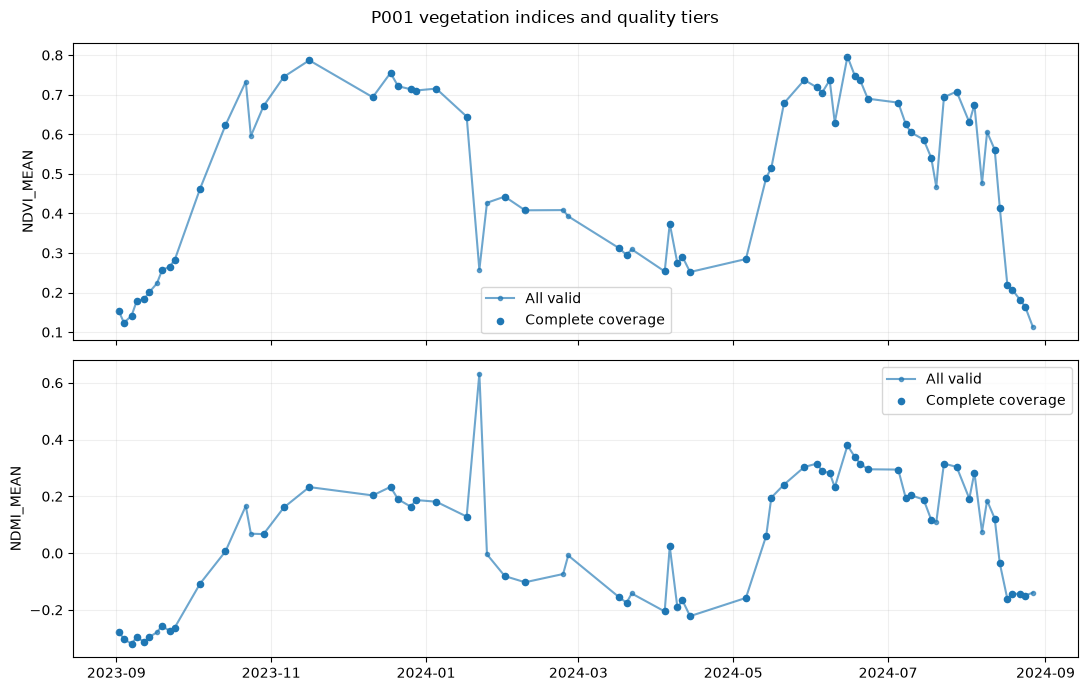

In [3]:
if observed is not None:
    for index in ('ndvi_mean','ndmi_mean'):
        print(index, 'all valid:',summary(valid,index),'complete:',summary(complete,index))
    fig,ax=plt.subplots(2,1,figsize=(11,7),sharex=True)
    for a,index in zip(ax,('ndvi_mean','ndmi_mean')):
        a.plot(valid.date,valid[index],'.-',label='All valid',alpha=.65)
        a.scatter(complete.date,complete[index],s=20,label='Complete coverage')
        a.set(ylabel=index.upper());a.grid(alpha=.2);a.legend()
    fig.suptitle('P001 vegetation indices and quality tiers');fig.tight_layout();plt.show()

## 4. Uneven temporal sampling, derivatives and smoothing

Divide the observed change by the actual number of elapsed days, not by the number of records. A 21-day time-window mean reduces short-term variability but is **not a prediction**.


NDVI rate (index units/day): count    69.000000
mean     -0.002015
std       0.028521
min      -0.077397
25%      -0.011215
50%      -0.001546
75%       0.008778
max       0.075639
dtype: float64


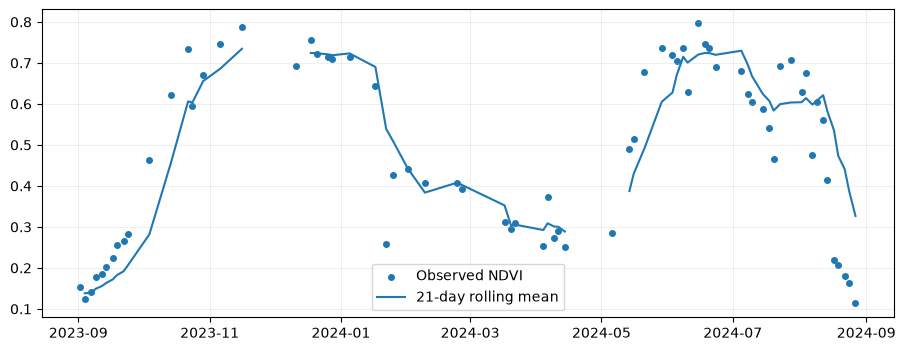

In-sample descriptive RMSE (not independent validation): 0.10473016682156085
Observed NDVI peak: {'date': Timestamp('2024-06-15 00:00:00+0000', tz='UTC'), 'ndvi_mean': 0.7963917339220643}


In [4]:
if observed is not None and len(valid)>2:
    v=valid.dropna(subset=['ndvi_mean']).sort_values('date')
    rates=rates_of_change(v.date,v.ndvi_mean)
    print('NDVI rate (index units/day):',pd.Series(rates).describe())
    smooth=rolling_time_mean(v,'ndvi_mean','21D')
    fig,ax=plt.subplots(figsize=(11,4));ax.scatter(v.date,v.ndvi_mean,s=16,label='Observed NDVI');ax.plot(smooth.index,smooth.values,label='21-day rolling mean');ax.legend();ax.grid(alpha=.2);plt.show()
    print('In-sample descriptive RMSE (not independent validation):',rmse(v.ndvi_mean,smooth.to_numpy()))
    peak=v.loc[v.ndvi_mean.idxmax(),['date','ndvi_mean']]
    print('Observed NDVI peak:',peak.to_dict())

## 5. Crop signatures, interpretation and limitations

Reference crop records indicate winter wheat in harvest years 2023 and 2025, and sunflower in 2024. The original September 2023–August 2024 data overlaps the **2024 sunflower analytical window** but does not cover the wheat harvest windows. Accordingly the wheat seasons **cannot be compared empirically** from the existing record.

Previously documented descriptive outputs indicated a June 15, 2024 NDVI peak near 0.80 and an NDMI peak near 0.38, with a lower late-summer index. A January 22 NDMI outlier near 0.63 was flagged under partial pixel coverage. These are **archived reported values, not newly verified here**. Without the CSV, they must not be presented as notebook-derived evidence.

Limits: one parcel, no independent reference parcels, partial seasonal windows, cloud-related missingness, possible mixed pixels, uncertain actual sowing/harvest dates, and daily aggregation buckets (not necessarily individual Sentinel-2 acquisition timestamps). Descriptive consistency is not proof of crop identity.


## 6. Results and conclusions

**Mathematical result:** Normalized indices, time-aware differences, QC-tier selection and rolling-window estimates form an interpretable analysis workflow. The notebook can test sensitivity to quality filtering once the original data is restored.

**Scientific conclusion:** A seasonal NDVI/NDMI curve can support retrospective crop verification, but does not independently identify wheat or sunflower on this parcel. The two missing wheat windows are explicitly unavailable. Future work should acquire the missing seasons and independent crop-reference parcels, and report out-of-sample predictive accuracy only after classification is actually performed.

## 7. References

- Rouse et al. (1974), *Monitoring vegetation systems in the Great Plains with ERTS*, NASA SP-351.
- Tucker (1979), *Red and photographic infrared linear combinations for monitoring vegetation*, Remote Sensing of Environment 8, 127–150.
- Gao (1996), *NDWI—A normalized difference water index for remote sensing of vegetation from space*, Remote Sensing of Environment 58, 257–266. (NDMI-type NIR/SWIR index.)
- Zadoks, Chang & Konzak (1974), *A decimal code for the growth stages of cereals*, Weed Research 14, 415–421.
- Schneiter & Miller (1981), *Description of sunflower growth stages*, Crop Science 21, 901–903.
- Copernicus Data Space Ecosystem / Sentinel Hub Statistical API documentation (verify current service terms and methods).

## 8. Self-assessment

**Formulation:** clear and limited to one parcel. **Mathematics:** explicit formulas, irregular time-series normalization, statistical summaries and smoothing. **Code:** separated into reusable modules with unit tests. **Data:** observational source must be recovered for all results to be reproducible. **Communication:** results, limitations, references and uncertainty are distinguished. **Integrity:** no claims of validated crop classification; no invented satellite measurements. **Remaining submission work:** attach genuine original data and verify at least 10 meaningful Git commits and repository publication.


## 7. Mathematical sensitivity experiment: QC filtering

To quantify the influence of incomplete parcel coverage, compare the means and standard deviations for all valid observations against observations with complete valid-pixel coverage. Define $\Delta\bar{x}=\bar{x}_{all}-\bar{x}_{complete}$. A nonzero value indicates sensitivity to selection, not necessarily bias: incomplete coverage may be nonrandom because atmospheric conditions and season influence the availability of observations.

In [5]:
if observed is not None:
    sensitivity = []
    for band in ("ndvi_mean", "ndmi_mean"):
        a, c = summary(valid, band), summary(complete, band)
        sensitivity.append({"index": band, "all_n": a["n"], "complete_n": c["n"],
                            "all_mean": a["mean"], "complete_mean": c["mean"],
                            "difference": a["mean"] - c["mean"]})
    display(pd.DataFrame(sensitivity).round(4))
else:
    print("No empirical sensitivity estimates: original observations are missing.")

,index,all_n,complete_n,all_mean,complete_mean,difference
0,ndvi_mean,70,58,0.4841,0.4979,-0.0138
1,ndmi_mean,70,58,0.0432,0.0420,0.0012


## 8. Reproducible synthetic validation (not satellite data)

To test the mathematical implementation independently from unavailable satellite files, construct a small, explicitly synthetic series with uneven sampling times. This is a **software validation exercise only** and does not contribute observations to the crop study.

In [6]:

from src.math_analysis import normalized_difference, rates_of_change, rmse

# Test the NDVI calculation
assert np.isclose(normalized_difference(0.6, 0.2), 0.5)

# Create synthetic observations with uneven time intervals
synth_t = pd.to_datetime(
    ["2024-06-01", "2024-06-03", "2024-06-08"],
    utc=True
)

synth_ndvi = np.array([0.30, 0.38, 0.43])

# Calculate daily rates before testing them
synth_rates = rates_of_change(synth_t, synth_ndvi)

assert np.allclose(synth_rates, [0.04, 0.01])

# Test RMSE
assert np.isclose(rmse([1, 2], [1, 2]), 0.0)

print("All mathematical validation tests passed!")
print("Daily NDVI rates:", synth_rates)


All mathematical validation tests passed!
Daily NDVI rates: [0.04 0.01]


## 9. Interpretation, limitations, and conclusion

**Previously recorded findings (not revalidated in this recovery):** The historical run reported 141 daily intervals, 70 valid observations, of which 58 were complete coverage. NDVI rose from approximately 0.29 (April 2024 monthly level) to 0.80 on 2024-06-15 and declined toward 0.39 in August. The June 15 NDMI was approximately 0.38. A January 22 NDMI spike around 0.63 was associated with partial coverage and flagged in the previous analysis. These numbers **must not** be presented as recomputed results when the original CSV is absent.

The partial 2024 sunflower-season trajectory is compatible with growth followed by senescence, but this is **not independent crop identification**. Winter wheat harvest seasons 2023 and 2025 are not sufficiently represented. The analysis uses one parcel, no external validation parcels, and uneven temporal sampling. A smoothed curve does not recover missing ground truth.

**Conclusion:** Normalized spectral indices, temporal derivatives, statistical summaries and coverage-tier sensitivity provide interpretable mathematical tools for retrospective vegetation analysis. Reliable crop verification would require more observation years and independently validated crop labels.

## 10. Sources and software attribution

1. Rouse, J. W., Haas, R. H., Schell, J. A., & Deering, D. W. (1974). *Monitoring vegetation systems in the Great Plains with ERTS*. NASA SP-351, 309–317.
2. Tucker, C. J. (1979). Red and photographic infrared linear combinations for monitoring vegetation. *Remote Sensing of Environment*, 8(2), 127–150. https://doi.org/10.1016/0034-4257(79)90013-0
3. Gao, B.-C. (1996). NDWI—A normalized difference water index for remote sensing of vegetation from space. *Remote Sensing of Environment*, 58(3), 257–266. https://doi.org/10.1016/S0034-4257(96)00067-3
4. Copernicus Data Space Ecosystem. Sentinel Hub Statistical API documentation. https://documentation.dataspace.copernicus.eu/APIs/SentinelHub/Statistical.html
5. ESA. Sentinel-2 mission documentation. https://sentinels.copernicus.eu/web/sentinel/missions/sentinel-2

Python implementation uses NumPy, pandas and Matplotlib. The restored `crop_signature.py` was recovered from a saved earlier programming session; other modules and notebook were reconstructed using AI assistance. The author must review, adapt, and attribute this assistance according to the course's academic integrity policy.

## 11. Self-assessment

| Assessment area | Evidence | Outstanding limitation |
|---|---|---|
| Problem formulation | CAP-context parcel-level retrospective vegetation analysis | Verification cannot be proven for one season |
| Mathematical understanding | Index equations, temporal derivatives, summary statistics, RMSE | No uncertainty model for independent crop prediction |
| Code quality | Modular functions, unit tests, independent notebook checks | API not live tested in this recovered environment |
| Methods and data handling | SCL masking, QA tiers, sensitivity experiment | Original observation CSV not recovered |
| Communication | English notebook, README, documented caveats, references | User must inspect before submission |
| Deliverables | Notebook and local source archive | GitHub URL and >=10 genuine commits require user action |

**Not a claim of a particular exam score.** Scientific outputs should be rerun from authentic input files before representing them as independently verified.